# Assignment: Creating Visualizations

All CSV files used in this notebook sit in the same folder as the notebook, so every file is loaded with a relative path (for example `pd.read_csv('steam_games.csv')`). To run it, unzip the folder and open the notebook from inside it.

Files in the folder:
- `Creating_Visualizations.ipynb` (this notebook)
- `steam_games.csv` (Part III, provided with the assignment)
- `co2_emissions_1990_2024.csv` (Part IV, my own data set)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

## Part I: Creating a Simple Figure

### Markers, line, and styling

The six made-up temperatures are in degrees Fahrenheit for January through June. The predicted line goes up by exactly 6 °F every month, so its slope never changes. The actual temperatures alternate above and below the line, which gives three points above and three points below it.

Points above the line: 3
Points below the line: 3
Slope between each month: [6 6 6 6 6]


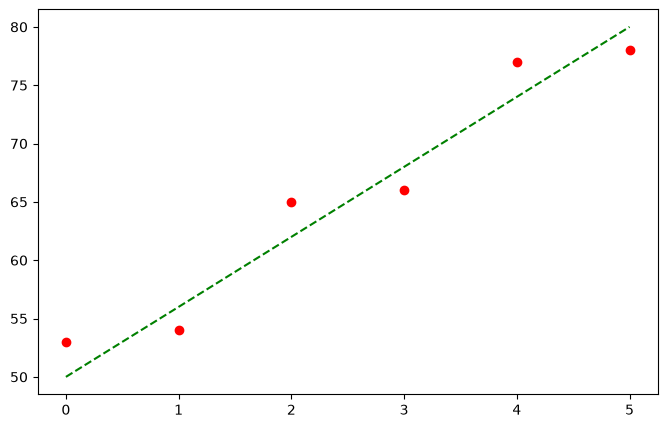

In [2]:
x = np.arange(6)  # six months: 0 = January ... 5 = June

# Predicted temperatures: straight line, constant slope of +6 degrees per month
predicted = np.array([50, 56, 62, 68, 74, 80])

# Actual temperatures: alternate above (+3) and below (-2) the line
actual = np.array([53, 54, 65, 66, 77, 78])

print('Points above the line:', np.sum(actual > predicted))
print('Points below the line:', np.sum(actual < predicted))
print('Slope between each month:', np.diff(predicted))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, actual, 'ro')                  # red circle markers
ax.plot(x, predicted, 'g--')              # dashed green line
plt.show()

### Labels, ticks, title, legend, and text box

Same code as above, with the tick, label, title, legend, and text box changes added.

To predict July, I extend the line one more step: 80 + 6 = 86 °F.

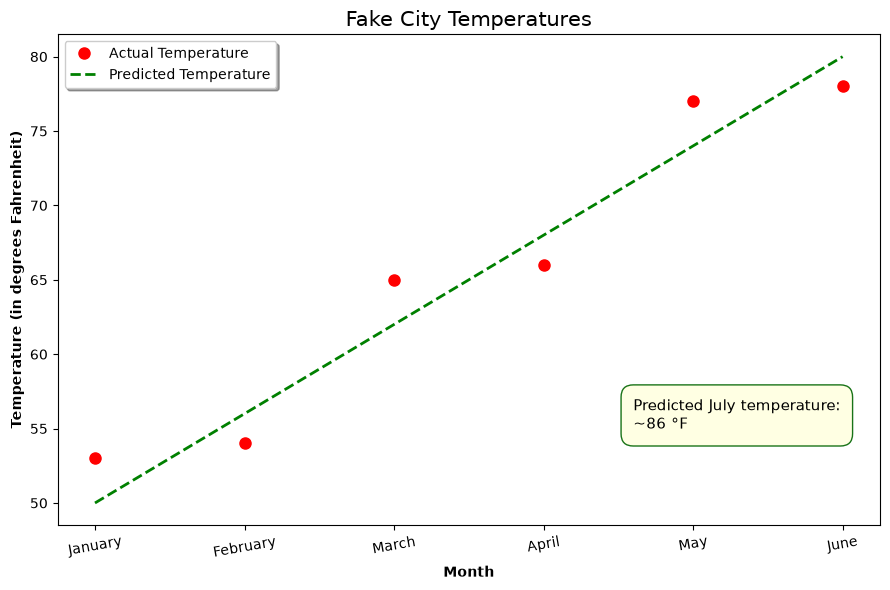

In [3]:
x = np.arange(6)
predicted = np.array([50, 56, 62, 68, 74, 80])
actual = np.array([53, 54, 65, 66, 77, 78])
months = ['January', 'February', 'March', 'April', 'May', 'June']

# Prediction for the next month (July) based on the line's constant slope
slope = predicted[1] - predicted[0]
next_month_prediction = predicted[-1] + slope

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(x, actual, 'ro', markersize=8, label='Actual Temperature')
ax.plot(x, predicted, 'g--', linewidth=2, label='Predicted Temperature')

# One tick per data point, labeled with the month name and rotated ten degrees
ax.set_xticks(x)
ax.set_xticklabels(months, rotation=10)

# Bold axis labels
ax.set_xlabel('Month', fontweight='bold')
ax.set_ylabel('Temperature (in degrees Fahrenheit)', fontweight='bold')

# Title with font size of fifteen
ax.set_title('Fake City Temperatures', fontsize=15)

# Legend with a shadow effect
ax.legend(shadow=True, loc='upper left')

# Text box with the July prediction (customized face color, padding, edge color, and box style)
ax.text(3.6, 55, f'Predicted July temperature:\n~{next_month_prediction} °F',
        fontsize=11,
        bbox=dict(facecolor='lightyellow', edgecolor='darkgreen',
                  boxstyle='round', pad=0.8, alpha=0.9))

plt.tight_layout()
plt.show()

**Prediction:** The predicted line rises 6 °F every month, so the next month (July) would be about **86 °F**. This is shown in the text box inside the figure.

## Part II: Using Real-World Data

Data source: [Wikipedia – List of United States cities by population](https://en.wikipedia.org/wiki/List_of_United_States_cities_by_population), viewed September 28, 2026. These are the top ten cities in the default order on the page, with the 2020 census count and the 2025 estimate for each.

In [4]:
cities = ['New York', 'Los Angeles', 'Chicago', 'Houston', 'Phoenix',
          'Philadelphia', 'San Antonio', 'San Diego', 'Dallas', 'Fort Worth']
states = ['NY', 'CA', 'IL', 'TX', 'AZ', 'PA', 'TX', 'CA', 'TX', 'TX']

pop_2020_raw = [8804190, 3898747, 2746388, 2304580, 1608139,
                1603797, 1434625, 1386932, 1304379, 918915]
pop_2025_raw = [8584629, 3869089, 2731585, 2397315, 1665481,
                1574281, 1548422, 1406106, 1329491, 1028117]

cities_df = pd.DataFrame({'City': cities, 'State': states,
                          'Census_2020': pop_2020_raw, 'Estimate_2025': pop_2025_raw})

# Convert to millions and round to two decimal places (e.g. 2,342,500 -> 2.34)
cities_df['Census_2020_M'] = (cities_df['Census_2020'] / 1_000_000).round(2)
cities_df['Estimate_2025_M'] = (cities_df['Estimate_2025'] / 1_000_000).round(2)
cities_df

,City,State,Census_2020,Estimate_2025,Census_2020_M,Estimate_2025_M
0,New York,NY,8804190,8584629,8.80,8.58
1,Los Angeles,CA,3898747,3869089,3.90,3.87
2,Chicago,IL,2746388,2731585,2.75,2.73
3,Houston,TX,2304580,2397315,2.30,2.40
4,Phoenix,AZ,1608139,1665481,1.61,1.67
5,Philadelphia,PA,1603797,1574281,1.60,1.57
6,San Antonio,TX,1434625,1548422,1.43,1.55
7,San Diego,CA,1386932,1406106,1.39,1.41
8,Dallas,TX,1304379,1329491,1.30,1.33
9,Fort Worth,TX,918915,1028117,0.92,1.03


### Bar chart

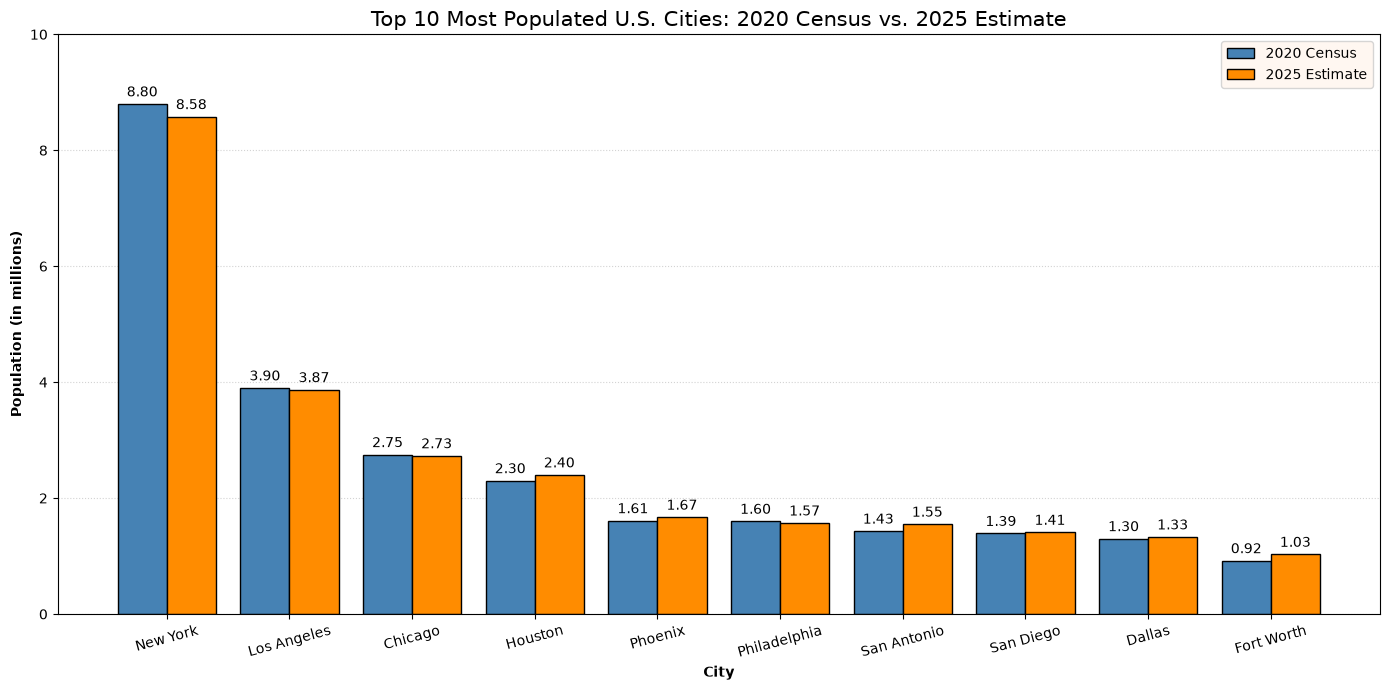

In [5]:
x = np.arange(len(cities_df))
width = 0.4

fig, ax = plt.subplots(figsize=(14, 7))
bars_2020 = ax.bar(x - width/2, cities_df['Census_2020_M'], width,
                   label='2020 Census', color='steelblue', edgecolor='black')
bars_2025 = ax.bar(x + width/2, cities_df['Estimate_2025_M'], width,
                   label='2025 Estimate', color='darkorange', edgecolor='black')

ax.set_title('Top 10 Most Populated U.S. Cities: 2020 Census vs. 2025 Estimate', fontsize=15)
ax.set_xlabel('City', fontweight='bold')
ax.set_ylabel('Population (in millions)', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(cities_df['City'], rotation=15)

# Legend with a seashell face color
ax.legend(facecolor='seashell')

# Major horizontal grid lines: light grey and dotted, drawn behind the bars
ax.yaxis.grid(True, which='major', color='lightgrey', linestyle=':')
ax.set_axisbelow(True)

# Population labels above each bar
ax.bar_label(bars_2020, fmt='%.2f', padding=3, fontsize=10)
ax.bar_label(bars_2025, fmt='%.2f', padding=3, fontsize=10)
ax.set_ylim(0, 10)

plt.tight_layout()
plt.show()

In [6]:
# Cities with an estimated increase from 2020 to 2025 (using the unrounded counts)
increased = cities_df[cities_df['Estimate_2025'] > cities_df['Census_2020']]
print('Cities with an estimated increase:', ', '.join(increased['City']))

# Cities in California
in_ca = cities_df[cities_df['State'] == 'CA']
print('California cities in the top ten:', len(in_ca), '->', ', '.join(in_ca['City']))

Cities with an estimated increase: Houston, Phoenix, San Antonio, San Diego, Dallas, Fort Worth
California cities in the top ten: 2 -> Los Angeles, San Diego


**Which city (or cities) had an estimated increase in population from 2020 to 2025?**

Six of the ten cities are estimated to have grown: **Houston, Phoenix, San Antonio, San Diego, Dallas, and Fort Worth**. Fort Worth grew the most in percentage terms (0.92 million to 1.03 million, about +12%), followed by San Antonio (about +8%). New York, Los Angeles, Chicago, and Philadelphia all show small estimated declines.

**How many of the cities in the top ten list are in California?**

**Two**: Los Angeles and San Diego.

### Pie chart (2020 Census)

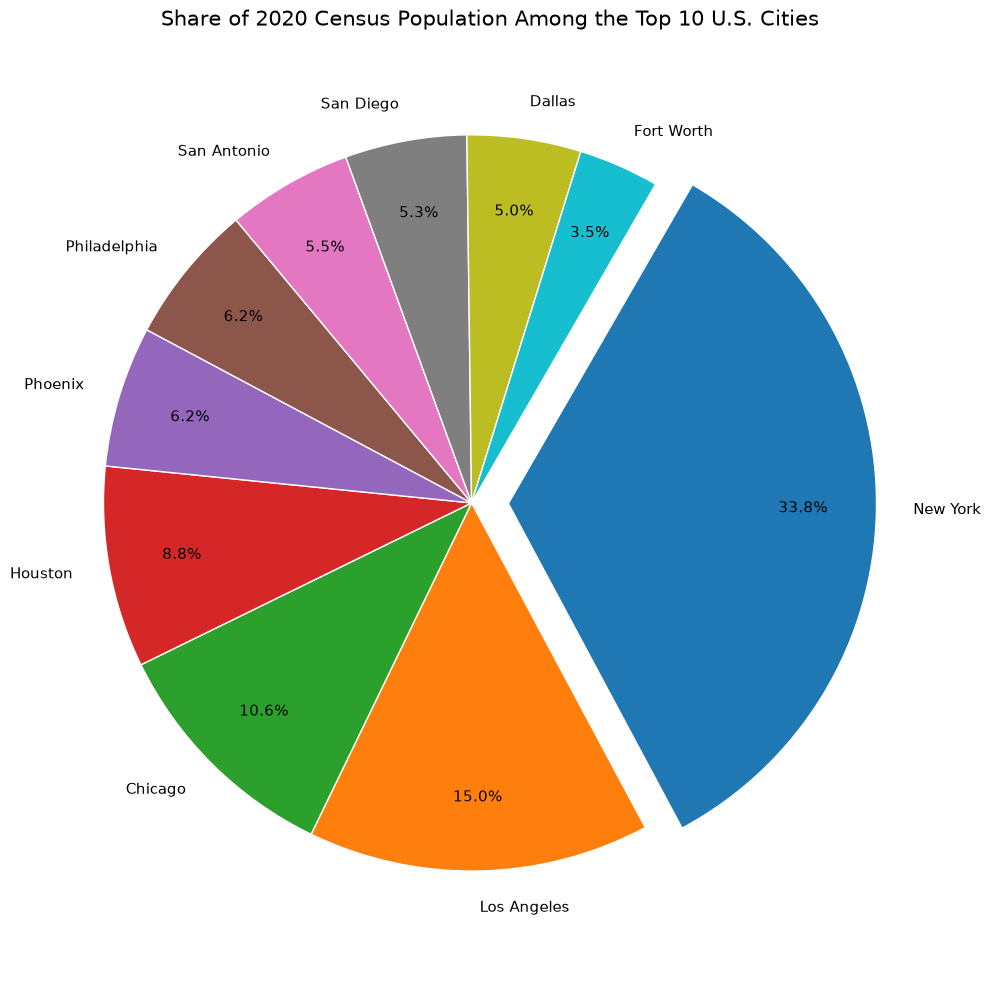

In [7]:
# Explode only the most populated city (New York)
explode = [0.1 if p == cities_df['Census_2020_M'].max() else 0
           for p in cities_df['Census_2020_M']]

fig, ax = plt.subplots(figsize=(10, 10))
ax.pie(cities_df['Census_2020_M'],
       labels=cities_df['City'],
       autopct='%1.1f%%',
       explode=explode,
       startangle=60,
       counterclock=False,        # clockwise direction
       pctdistance=0.8,
       textprops={'fontsize': 11},
       wedgeprops={'edgecolor': 'white'})
ax.set_title('Share of 2020 Census Population Among the Top 10 U.S. Cities', fontsize=15)
ax.axis('equal')
plt.tight_layout()
plt.show()

**Additional conclusions from the two charts**

- New York is in a class of its own. In 2020 it had about 34% of the combined population of all ten cities, more than Los Angeles and Chicago put together. Even after its estimated decline to 8.58 million, it is still more than twice the size of Los Angeles.
- Texas is where the growth is happening. Four of the ten cities are in Texas (Houston, San Antonio, Dallas, Fort Worth), and all four are estimated to have grown. The cities that lost population are the older, larger Northeast, Midwest, and West Coast cities (New York, Chicago, Philadelphia, Los Angeles).
- Houston is getting closer to Chicago. The gap between the #3 and #4 cities shrank from about 0.44 million in 2020 to about 0.33 million in 2025. If the trend continues, Houston could pass Chicago in the next several years.
- The pie chart shows how top-heavy the list is. Cities 5 through 10 each have only about 3.5–6% of the total, so their slices look almost the same size. The bar chart is better for comparing those cities to each other and for seeing change over time. The pie chart only shows one year, and it's better for showing each city's share of the whole.

## Part III: Working with Data Frames in Pandas

### Loading and cleaning the data

`Price` is stored as text like `"$23.99 "` and `Metascore` as text like `"90.00%"`. To plot them as numbers, I remove the `$` and `%` symbols with `str.replace()`, trim any extra spaces with `str.strip()`, and convert the columns to floats with `astype(float)`.

In [8]:
games = pd.read_csv('steam_games.csv')   # relative path, same folder as the notebook
print(games.dtypes)
games.head()

Metascore                 str
Price                     str
Game_Type                 str
Game                      str
Owners                    str
Average_Hours_Played    int64
Median_Hours_Played     int64
Publishers                str
dtype: object


,Metascore,Price,Game_Type,Game,Owners,Average_Hours_Played,Median_Hours_Played,Publishers
0,90.00%,$0.00,Strategy,Counter-Strike: Global Offensive,"200,000,000",26,16,Valve
1,96.00%,$0.00,Action,Dota 2,"200,000,000",26,16,Valve
2,70.00%,$23.99,RPG,Team Fortress 2,"100,000,000",33,25,Amazon Games
3,70.00%,$23.99,Adventure,ARK: Survival Evolved,"100,000,000",33,25,Amazon Games
4,96.00%,$23.99,Action,PUBG: BATTLEGROUNDS,"100,000,000",33,25,Amazon Games


In [9]:
games['Price'] = (games['Price'].str.replace('$', '', regex=False)
                                .str.strip()
                                .astype(float))
games['Metascore'] = (games['Metascore'].str.replace('%', '', regex=False)
                                        .str.strip()
                                        .astype(float))

print(games[['Price', 'Metascore']].dtypes)
print()
print(games['Game_Type'].value_counts())
games[['Price', 'Metascore', 'Average_Hours_Played']].describe().round(2)

Price        float64
Metascore    float64
dtype: object

Game_Type
Action        384
Indie         167
Adventure     157
Strategy      112
RPG           107
Simulation    100
Sports         14
Name: count, dtype: int64


,Price,Metascore,Average_Hours_Played
count,1041.00,1041.00,1041.00
mean,21.00,78.78,6.54
std,15.13,8.98,8.45
min,0.00,37.00,1.00
25%,9.99,74.00,2.00
50%,19.99,80.00,3.00
75%,29.99,85.00,7.00
max,69.99,97.00,66.00


### Scatter plot

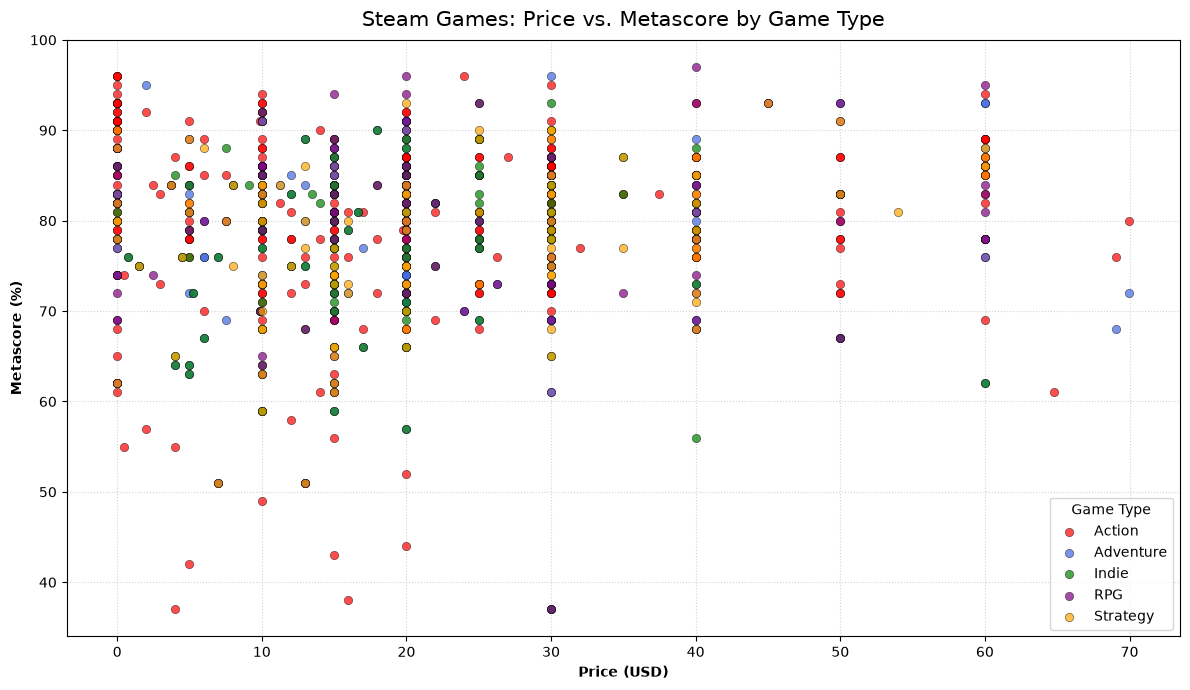

In [10]:
# Five game types, each with a manually chosen marker color
type_colors = {
    'Action':    'red',
    'Adventure': 'royalblue',
    'Indie':     'green',
    'RPG':       'purple',
    'Strategy':  'orange',
}

fig, ax = plt.subplots(figsize=(12, 7))
for game_type, color in type_colors.items():
    subset = games[games['Game_Type'] == game_type]
    ax.scatter(subset['Price'], subset['Metascore'], color=color,
               label=game_type, alpha=0.7, edgecolors='black', linewidths=0.4)

ax.set_title('Steam Games: Price vs. Metascore by Game Type', fontsize=15, pad=10)
ax.set_xlabel('Price (USD)', fontweight='bold')
ax.set_ylabel('Metascore (%)', fontweight='bold')
ax.legend(title='Game Type', loc='lower right')
ax.grid(color='lightgrey', linestyle=':')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [11]:
# Supporting numbers used in the written analysis below
plotted = games[games['Game_Type'].isin(type_colors.keys())].copy()
print('Games plotted:', len(plotted))
print('Rows that share an exact (Price, Metascore) pair with another row:',
      plotted.duplicated(['Price', 'Metascore']).sum())
print('Correlation between price and metascore:',
      round(plotted['Price'].corr(plotted['Metascore']), 2))
print()
print(plotted.groupby('Game_Type')[['Price', 'Metascore']].agg(['mean', 'median']).round(1))
print()
print('Free games by type:')
print(plotted[plotted['Price'] == 0]['Game_Type'].value_counts())

Games plotted: 927
Rows that share an exact (Price, Metascore) pair with another row: 597
Correlation between price and metascore: 0.09

          Price        Metascore       
           mean median      mean median
Game_Type                              
Action     21.0   20.0      80.6   82.0
Adventure  20.7   20.0      77.9   79.0
Indie      18.5   18.0      77.2   79.0
RPG        22.3   20.0      78.8   80.0
Strategy   22.1   20.0      77.7   79.0

Free games by type:
Game_Type
Action       61
RPG          12
Adventure     8
Strategy      7
Indie         6
Name: count, dtype: int64


**What are some potential shortcomings that you can see for this visualization?**

- **Overplotting.** Prices cluster at standard price points ($9.99, $19.99, $29.99, etc.), and metascores are whole numbers, so hundreds of games land on the exact same spot. Nearly 600 of the 927 plotted games share a (price, metascore) pair with another game. Only the color drawn last shows, so the plot hides how many games are at each point and makes some game types look smaller than they are.
- **Uneven group sizes.** Action has 384 games, while RPG and Strategy have only about 110 each. The red points take over the chart and make it hard to see patterns in the smaller groups.
- **Too many colors in one space.** With five overlapping categories, it's hard to compare any two game types directly.
- **Genre labels are simplified.** Each game gets only one `Game_Type`, but many games fit more than one genre (an "Indie" game can also be an RPG). So the colors are a simplification. For example, Team Fortress 2 is labeled RPG.
- **Missing context.** The plot doesn't show prices changing over time, sales, or discounts, so "price" here is one snapshot.

**What are some fixes that you would propose for these shortcomings?**

- Add **transparency and jitter** (a small random offset) so stacked points spread out, or switch to a **hexbin / 2D density plot** to show where games are concentrated.
- Use **small multiples** (one subplot per game type with shared axes) so each genre can be read on its own without overlap.
- Add summary markers, such as each genre's **mean or median** price and metascore, or show a **box plot of metascore per genre** next to the scatter.
- Sample the larger groups or normalize them so Action doesn't dominate. Or use fewer, more distinct categories.
- Add annotations for notable outliers (for example, very low-scoring games) so readers can tell what they are.

**Takeaways from the plot**

- **Price doesn't predict quality.** The correlation between price and metascore is close to zero (about 0.09). Games scoring in the 90s appear at $0, $20, and $60, and poorly reviewed games appear at every price.
- **Most games are priced at or under $30 and score between about 70 and 90.** The densest part of the chart is in that range. Games over $40 are much less common, and very few scores are under 60.
- **Free-to-play is mostly Action.** The line of points at $0 is mostly red. 61 of the 94 free games plotted are Action games, including high scorers like Dota 2 (96) and Counter-Strike: Global Offensive (90).
- **Action games have a slightly higher average metascore** (about 80.6) than the other plotted types (about 77–79), but the difference is small compared with the spread inside each type.

### Bubble plot

Bubble size is based on `Average_Hours_Played`. Average hours range from 1 to 66, so raw values would make most bubbles tiny. I scale the size as `Average_Hours_Played * 12 + 10`. The multiplier makes the differences visible, the small base of 10 keeps 1-hour games from disappearing, and bubble area still grows in direct proportion to hours played. I use transparency so overlapping bubbles stay readable. In the legend, the color markers are set to one uniform size, and a second legend shows what the bubble sizes mean.

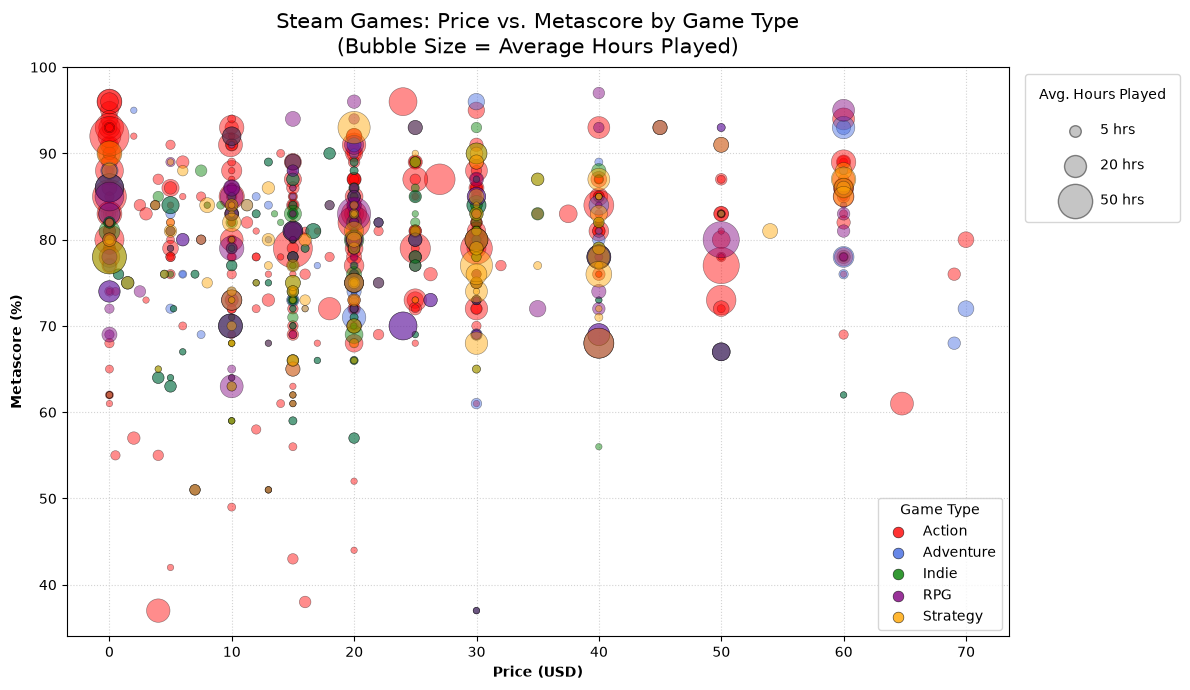

In [12]:
size_scale = 12
size_base = 10

fig, ax = plt.subplots(figsize=(12, 7))
for game_type, color in type_colors.items():
    subset = games[games['Game_Type'] == game_type]
    ax.scatter(subset['Price'], subset['Metascore'],
               s=subset['Average_Hours_Played'] * size_scale + size_base,
               color=color, label=game_type, alpha=0.45,
               edgecolors='black', linewidths=0.4)

ax.set_title('Steam Games: Price vs. Metascore by Game Type\n(Bubble Size = Average Hours Played)',
             fontsize=15, pad=10)
ax.set_xlabel('Price (USD)', fontweight='bold')
ax.set_ylabel('Metascore (%)', fontweight='bold')

# Game-type legend (same as the scatter plot): lower right, with a title
type_legend = ax.legend(title='Game Type', loc='lower right')
for handle in type_legend.legend_handles:
    handle.set_sizes([60])
    handle.set_alpha(0.8)
ax.add_artist(type_legend)

# Extra legend explaining the bubble sizes
size_handles = [ax.scatter([], [], s=h * size_scale + size_base, color='grey',
                           alpha=0.45, edgecolors='black')
                for h in (5, 20, 50)]
ax.legend(size_handles, ['5 hrs', '20 hrs', '50 hrs'], title='Avg. Hours Played',
          loc='upper left', bbox_to_anchor=(1.01, 1), labelspacing=1.5, borderpad=1)

ax.grid(color='lightgrey', linestyle=':')
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [13]:
# Supporting numbers for the bubble-plot analysis
print('Correlation between metascore and average hours played:',
      round(plotted['Metascore'].corr(plotted['Average_Hours_Played']), 2))
print('Correlation between price and average hours played:',
      round(plotted['Price'].corr(plotted['Average_Hours_Played']), 2))
print()
print(plotted.groupby('Game_Type')['Average_Hours_Played'].agg(['mean', 'median', 'max']).round(1))
print()
plotted['Score_Band'] = pd.cut(plotted['Metascore'], bins=[0, 70, 80, 90, 100],
                               labels=['Under 70', '70-79', '80-89', '90+'])
print(plotted.groupby('Score_Band', observed=True)['Average_Hours_Played'].mean().round(1))

Correlation between metascore and average hours played: 0.15
Correlation between price and average hours played: 0.07

           mean  median  max
Game_Type                   
Action      7.0     3.0   66
Adventure   5.5     3.0   38
Indie       4.7     3.0   49
RPG         8.7     5.0   56
Strategy    7.5     4.0   49

Score_Band
Under 70     5.3
70-79        6.5
80-89        6.4
90+         11.7
Name: Average_Hours_Played, dtype: float64


**Do you prefer this bubble plot over the original scatter plot? Why or why not?**

It depends on the question, but for this data set I slightly prefer the original scatter plot for comparing price and metascore. The bubble plot makes the overplotting problem worse: large bubbles cover the small ones and the points around them, and the middle of the chart turns into a blob of overlapping colors. Still, the bubble plot is useful because it adds a third variable without another chart, and it makes the high-engagement games stand out right away. If I had to present it, I'd use the bubble plot for a "which games keep players busy" story and the scatter plot for a "does price relate to quality" story.

**Using this additional dimension (bubble size), what other conclusion(s) can be drawn?**

- **Higher-rated games tend to be played longer, but the relationship is weak.** The biggest bubbles are mostly in the upper half of the chart. On average, games scoring 90+ are played about 11.7 hours, compared with about 5.3 hours for games scoring under 70, but the correlation is only about 0.15. A good score doesn't guarantee a long play time.
- **Price has almost nothing to do with play time.** Large bubbles show up at $0, in the $10–$30 range, and above $40. Paying more doesn't mean players spend more hours with a game, and some free games have strong engagement.
- **RPG and Strategy games tend to be played the longest** on average (about 8.7 and 7.5 hours), which fits genres built around long campaigns and replayability. Indie games have the smallest bubbles on average (about 4.7 hours).
- **Most games have small bubbles.** Most games average only a few hours, and a small number of titles with 40–66 hours pull the averages up. Average hours is a skewed measure.

## Part IV: Choose Your Own Adventure

### About the data

**File:** `co2_emissions_1990_2024.csv` (included in the zip folder)

**Source:** [Our World in Data – CO₂ and Greenhouse Gas Emissions data set](https://github.com/owid/co2-data), downloaded from the `owid-co2-data.csv` file in their public GitHub repository. Our World in Data builds this data set mainly from the Global Carbon Project's fossil CO₂ emissions estimates, combined with population data. The full file covers every country from 1750 onward and is about 14 MB. I narrowed it down to the six largest emitters (China, the United States, India, the European Union as a group, Russia, and Japan) for the years 1990–2024, which gives 210 rows.

**Variables:**
| Column | Meaning |
|---|---|
| `country` | Country or region name (the EU 27 is treated as one region) |
| `iso_code` | Three-letter ISO country code (blank for the EU because it is a group, not a country) |
| `year` | Calendar year (1990–2024) |
| `population` | Total population |
| `co2` | Annual CO₂ emissions from fossil fuels and industry, in **million tonnes** |
| `co2_per_capita` | Annual CO₂ emissions per person, in **tonnes per person** |

In [14]:
co2 = pd.read_csv('co2_emissions_1990_2024.csv')   # relative path
print(co2.shape)
print(co2['country'].unique())
co2.head()

(210, 6)
<StringArray>
['China', 'European Union (27)', 'India', 'Japan', 'Russia', 'United States']
Length: 6, dtype: str


,country,iso_code,year,population,co2,co2_per_capita
0,China,CHN,1990,1.153583e+09,2483.534,2.153
1,China,CHN,1991,1.170789e+09,2619.143,2.237
2,China,CHN,1992,1.184574e+09,2731.290,2.306
3,China,CHN,1993,1.197309e+09,2914.284,2.434
4,China,CHN,1994,1.209003e+09,3093.891,2.559


### Visualization

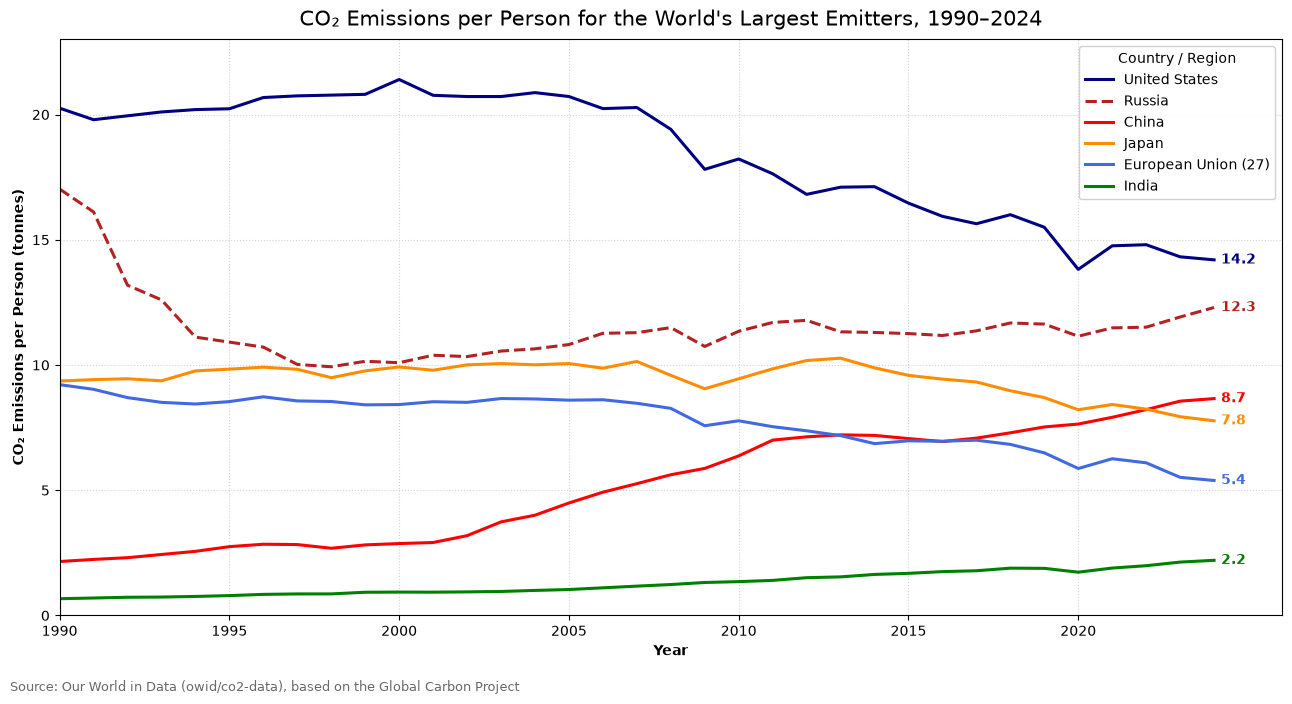

In [15]:
per_capita = co2.pivot(index='year', columns='country', values='co2_per_capita')

# Fixed order and colors so the legend matches the lines from highest to lowest in 2024
order = ['United States', 'Russia', 'China', 'Japan', 'European Union (27)', 'India']
colors = {'United States': 'navy', 'Russia': 'firebrick', 'China': 'red',
          'Japan': 'darkorange', 'European Union (27)': 'royalblue', 'India': 'green'}
styles = {'China': '-', 'Russia': '--'}

fig, ax = plt.subplots(figsize=(13, 7))
for country in order:
    ax.plot(per_capita.index, per_capita[country], label=country,
            color=colors[country], linewidth=2.2,
            linestyle=styles.get(country, '-'))
    # Label the 2024 value at the end of each line
    last = per_capita[country].iloc[-1]
    ax.annotate(f'{last:.1f}', xy=(2024, last), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=10,
                color=colors[country], fontweight='bold')

ax.set_title('CO₂ Emissions per Person for the World\'s Largest Emitters, 1990–2024',
             fontsize=15, pad=10)
ax.set_xlabel('Year', fontweight='bold')
ax.set_ylabel('CO₂ Emissions per Person (tonnes)', fontweight='bold')
ax.set_xlim(1990, 2026)
ax.set_xticks(range(1990, 2025, 5))
ax.set_ylim(0, 23)
ax.grid(color='lightgrey', linestyle=':')
ax.set_axisbelow(True)
ax.legend(title='Country / Region', loc='upper right', facecolor='white', framealpha=0.9)

fig.text(0.01, 0.005, 'Source: Our World in Data (owid/co2-data), based on the Global Carbon Project',
        fontsize=9, color='dimgray')

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

In [16]:
# Supporting numbers for the analysis
summary = per_capita.loc[[1990, 2000, 2010, 2024], order].round(2).T
summary['Change 1990-2024 (%)'] = ((per_capita.loc[2024, order] / per_capita.loc[1990, order] - 1) * 100).round(1)
summary

year,1990,2000,2010,2024,Change 1990-2024 (%)
country,,,,,
United States,20.25,21.40,18.23,14.20,-29.9
Russia,17.02,10.09,11.35,12.30,-27.8
China,2.15,2.87,6.37,8.66,302.1
Japan,9.36,9.92,9.45,7.77,-17.0
European Union (27),9.22,8.42,7.77,5.39,-41.5
India,0.67,0.93,1.35,2.20,229.5


### Why a line chart?

The data is a **time series**: the same measurement (CO₂ per person) recorded every year for six regions. A line chart is the clearest way to show trends over time. You can see whether each line goes up or down, how fast it changes, and where lines cross, which is where the most interesting part of this data is. A bar chart with 35 years × 6 regions would have 210 bars and be hard to read, and a pie chart can only show one year's share of a total. I used per-person emissions instead of total emissions so that regions with very different populations (India at 1.4 billion people vs. Japan at about 124 million) can be compared fairly. I also labeled each line's 2024 value so readers don't have to estimate from the y-axis.

### Analysis and conclusions

- **The United States still has the highest per-person emissions of the group, but it's falling.** U.S. emissions peaked around 21.4 tonnes per person in 2000 and fell to about 14.2 tonnes by 2024, a drop of roughly 30% from 1990. The EU (−42%) and Japan (−17%) also declined. These declines line up with the move away from coal toward natural gas and renewables, plus gains in efficiency.
- **China's per-person emissions quadrupled.** They went from about 2.2 tonnes in 1990 to 8.7 tonnes in 2024. The steepest rise came in the 2000s, during China's rapid industrial growth. China passed the EU around 2013 and is now above Japan too. Combined with its large population, this is why China is now the world's largest total emitter.
- **Russia's line shows a big economic event.** Russia's per-person emissions dropped from about 17 to 10 tonnes in the 1990s after the Soviet Union collapsed, and they have slowly climbed back to about 12.3 since then.
- **India is still very low per person but rising steadily.** At about 2.2 tonnes, the average person in India emits around one-sixth as much as the average American. But India's line has gone up every decade (more than tripling since 1990). Because of its population size, even small increases per person add a lot to global totals.
- **The regions are becoming more similar.** In 1990 the range was about 0.7 to 20 tonnes. In 2024, most of the group (China, Japan, the EU) sits in a tighter 5–9 tonne band, while the U.S. and Russia remain the high outliers.